# Lab05 · El cuaderno de la tienda
**¿Están listos estos datos para enseñar a un modelo?** — INF670 · Introducción a Ciencia de Datos e IA · UATF

1. Escribe tu identificador en `ESTUDIANTE` (celda de inicio).
2. Ejecuta las celdas de código **en orden** con `Shift+Enter`.
3. Responde en las celdas ✍️ (doble clic para editar).
4. No modifiques `planilla_paltas.csv`: en este laboratorio se revisa y se documenta; no se corrige.

> Datos sintéticos, creados con fines didácticos.

## Celda de inicio

In [1]:
from pathlib import Path
import sys, hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ESTUDIANTE = "adalid@portillo"   # Escribe aqui tu identificador.
BASE = Path.cwd()
ARCHIVO = BASE / "planilla_paltas.csv"
SALIDAS = BASE / "salidas"
SALIDAS.mkdir(exist_ok=True)
HUELLA_INICIAL = hashlib.sha256(ARCHIVO.read_bytes()).hexdigest()

print("Estudiante:", ESTUDIANTE)
print("Entorno virtual activo:", sys.prefix != sys.base_prefix)
print("Planilla encontrada:", ARCHIVO.exists())

Estudiante: adalid@portillo
Entorno virtual activo: True
Planilla encontrada: True


## Tarea 1 · Abrir la planilla

In [2]:
df = pd.read_csv(ARCHIVO, encoding="utf-8")
print("Filas y columnas:", df.shape)
display(df.head())

diccionario = pd.read_csv(BASE / "diccionario_paltas.csv", encoding="utf-8")
display(diccionario)

Filas y columnas: (41, 8)


,id,fecha,proveedor,variedad,peso_g,firmeza,dias_cosecha,madura
0,P001,2026-10-01,Proveedor B,Hass,173.0,9,11,Sí
1,P002,2026-10-01,Proveedor C,Hass,229.0,4,3,No
2,P003,2026-10-01,Proveedor A,Criolla,341.0,8,10,Sí
3,P004,2026-10-01,Proveedor B,Hass,210.0,8,10,Sí
4,P005,2026-10-01,Proveedor C,Hass,214.0,3,2,No


,columna,significado,unidad o valores permitidos
0,id,Código de la palta registrada,"P001, P002…; uno distinto por palta"
1,fecha,Día en que se registró la palta,AAAA-MM-DD
2,proveedor,Quién entregó el lote,"Proveedor A, Proveedor B o Proveedor C"
3,variedad,Tipo de palta,Hass o Criolla
4,peso_g,Peso de la palta,"Gramos, entre 100 y 500"
5,firmeza,Cuánto cede al presionarla con el pulgar,Entero de 1 (muy dura) a 10 (muy blanda)
6,dias_cosecha,Días transcurridos desde la cosecha,Entero de 0 a 30
7,madura,¿Lista para consumir? (lo decide una persona a...,Sí o No (exactamente así)


### ✍️ Respuesta 1

(a) ¿Cuántas filas y columnas tiene la planilla? (b) ¿Qué representa una fila? (c) ¿En qué unidad está `peso_g` y qué significa `firmeza = 9`? (d) ¿Qué columna anotó una persona después de probar la palta?

*(a): Hay 41 filas y 8 columnas en la planilla*

*(b): planilla_paltas ->> cada fila es una palta registrada en la planilla*

*(c): gramos; 9 significa una `dureza` mayor al promedio (comprobamos con df.describe en la celda de abajo)*

*(d): madura*

In [3]:
df.describe()

,peso_g,firmeza,dias_cosecha
count,40.00000,41.000000,41.000000
mean,250.40600,6.585366,7.609756
std,73.74618,2.636054,3.300591
min,0.24000,1.000000,1.000000
25%,200.00000,5.000000,5.000000
50%,229.00000,6.000000,8.000000
75%,316.00000,8.000000,10.000000
max,369.00000,15.000000,12.000000


<Axes: >

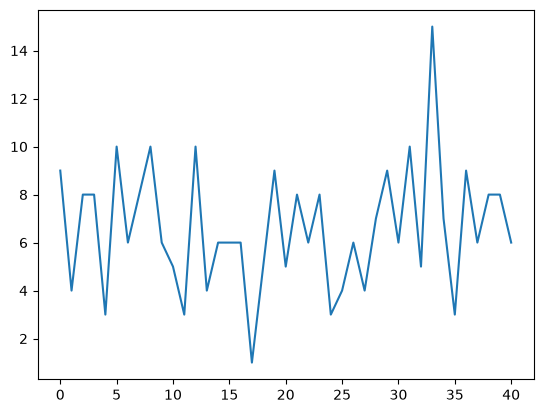

In [4]:
#segun describe el max es 15. Vemos outliers para ver el problema graficamente
df['firmeza'].plot()

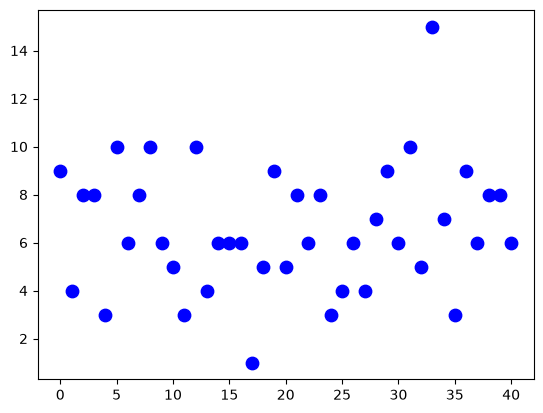

In [5]:
#efectivamente solo hay uno. Comprobamos con Scatter
plt.scatter(df.index, df['firmeza'], color='blue', s=80, label='Firmeza')

## Tarea 2 · Preguntar y ver
**Pregunta:** ¿las paltas maduras son más blandas que las que no están maduras?

### ✍️ Mi hipótesis (antes de graficar)

¿Qué esperas ver en el gráfico?

*firmeza segun madurez, es decir en x las maduras; en y firmezas. Tendriamos que ver un grafico de puntos como hice arriba pero esta vez usando dos columnas*

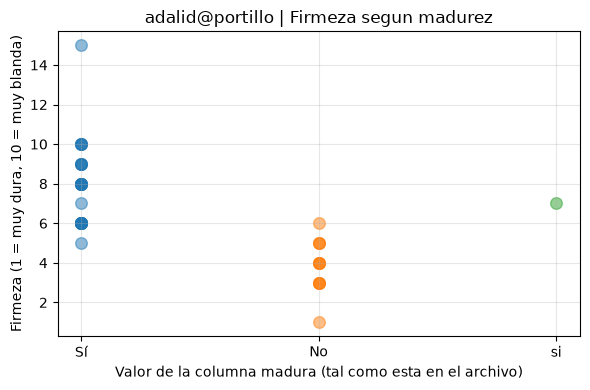

In [6]:
plt.figure(figsize=(6, 4))
for etiqueta in df["madura"].dropna().unique():
    grupo = df[df["madura"] == etiqueta]
    plt.scatter([etiqueta] * len(grupo), grupo["firmeza"], s=70, alpha=0.5)
plt.title(f"{ESTUDIANTE} | Firmeza segun madurez")
plt.xlabel("Valor de la columna madura (tal como esta en el archivo)")
plt.ylabel("Firmeza (1 = muy dura, 10 = muy blanda)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(SALIDAS / "firmeza_segun_madurez.png", dpi=150)
plt.show()

### ✍️ Respuesta 2

(a) ¿Se cumplió tu hipótesis? (b) ¿Desde qué valor de firmeza aparecen casi solo paltas maduras? (c) ¿Qué ves en el gráfico que no debería estar ahí?

*(a): si pero yo pensaba que seria mas disperso, tiene sentido porque solo son 3 columnas en 'madura'*

*(b): 5 aprox*

*(c): el 3er 'si', al igual que 15 que habiamos notado anteriormente cosiderando que es una evaluacion de 1-10*

## Tarea 3 · Revisar la calidad
Ejecuta cada revisión y anota lo que encuentres en la tabla de hallazgos.

In [7]:
# Revision 1: datos faltantes
print("Datos faltantes por columna:")
print(df.isna().sum())
display(df[df.isna().any(axis=1)])

Datos faltantes por columna:
id              0
fecha           0
proveedor       0
variedad        0
peso_g          1
firmeza         0
dias_cosecha    0
madura          0
dtype: int64


,id,fecha,proveedor,variedad,peso_g,firmeza,dias_cosecha,madura
6,P007,2026-10-02,Proveedor B,Hass,NaN,6,8,Sí


In [8]:
# Revision 2: filas repetidas
print("Filas repetidas:", df.duplicated().sum())
display(df[df.duplicated(keep=False)])

Filas repetidas: 1


,id,fecha,proveedor,variedad,peso_g,firmeza,dias_cosecha,madura
14,P015,2026-10-03,Proveedor A,Criolla,314.0,6,8,Sí
15,P015,2026-10-03,Proveedor A,Criolla,314.0,6,8,Sí


In [9]:
# Revision 3: peso fuera del rango del diccionario (100 a 500 g)
peso_fuera = (df["peso_g"] < 100) | (df["peso_g"] > 500)
display(df[peso_fuera])

,id,fecha,proveedor,variedad,peso_g,firmeza,dias_cosecha,madura
22,P022,2026-10-05,Proveedor B,Hass,0.24,6,6,Sí


In [10]:
# Revision 4: valores escritos en la columna madura
print(df["madura"].value_counts())

madura
Sí    27
No    13
si     1
Name: count, dtype: int64


In [11]:
# Revision 5 (reto): escribe tu propio filtro.
# Muestra las filas con firmeza fuera de la escala 1-10.
# Usa como modelo la Revision 3. No modifiques df.

In [12]:
#como ya vimos que hay un outlier, mostramos esa fila donde encuentre a >10
df[df['firmeza'] > 10]

,id,fecha,proveedor,variedad,peso_g,firmeza,dias_cosecha,madura
33,P033,2026-10-07,Proveedor A,Criolla,332.0,15,11,Sí


### ✍️ Tabla de hallazgos

| N.º | id | Columna y valor | Regla del diccionario que incumple | Por qué es un problema |
|---|---|---|---|---|
| 1 | P007 | Peso_g:NAN | 100<=gramos<=500 | requiere de pasos adicionales para asignarle un peso  |
| 2 | P015 | 14 == 15 | uno distinto por palta | altera resultados |
| 3 | P022 | Peso_g:0.24 | palta recien nacida | aun no debe ser estudiado |
| 4 | Y/N | Yes/No/ye | debe ser exactamente 'Si' o 'No' | crea un nuevo 'si' |
| 5 | P033 | firmeza:15 | 1-10 | no esta en el rango debido |

## Tarea 4 · Puente al Tema 3

### ✍️ Respuesta 4

(a) Si un modelo quisiera reconocer paltas maduras, ¿cuál sería la variable objetivo y cuáles las características? (b) ¿Por qué `id` no debería ser una característica? (c) Elige dos hallazgos y explica qué aprendería mal el modelo si no se revisaran.

*(a): variable objetivo = madura; caracteristicas = todas las anteriores excepto 'id'*

*(b): es propio de la planilla, no de la palta*

*(c): 1.- firmeza: entrenaria con valores atipicos. 2.- peso_g: al no estar en el rango serria otro atipico *

## Tarea 5 · Dictamen

### ✍️ Dictamen

¿La planilla está **LISTA**, **LISTA CON RESERVAS** o **NO LISTA** para entrenar un modelo que reconozca paltas maduras? Justifica en 80-120 palabras citando al menos tres `id` de tu tabla de hallazgos.

*LISTA CON RESERVAS.*

* P007 requiere pasos con .median()*

* P015 es ducplicado por lo tanto necesita remove de esos duplicated*

* P022 debe estar en un rango. necesita min max scaling*

* Y/N necesita de un normalizador para errores de typeo*

## Evidencia final
Ejecuta esta celda al terminar y toma la captura de pantalla que pide la guía.

In [13]:
import platform, datetime
assert ESTUDIANTE != "ID_ASIGNADO", "Escribe tu identificador en la celda de inicio."
huella_final = hashlib.sha256(ARCHIVO.read_bytes()).hexdigest()
codigo = hashlib.sha256((ESTUDIANTE + huella_final[:12]).encode()).hexdigest()[:8].upper()
print("Estudiante:", ESTUDIANTE)
print("Equipo (VM):", platform.node())
print("Fecha y hora:", datetime.datetime.now().strftime("%Y-%m-%d %H:%M"))
print("Planilla sin modificar:", huella_final == HUELLA_INICIAL)
print("Codigo de verificacion:", codigo)
print("Graficos guardados:", [p.name for p in SALIDAS.glob("*.png")])

Estudiante: adalid@portillo
Equipo (VM): 048
Fecha y hora: 2026-11-15 15:57
Planilla sin modificar: True
Codigo de verificacion: 79F00101
Graficos guardados: ['firmeza_segun_madurez.png']


### Declaración de uso de IA
Si consultaste una IA, indica para qué y cómo comprobaste la respuesta. Si no la usaste, escribe «No utilicé IA».

--->GEMINI FLASH LITE; para graficos con matplotlib en celdas 8-9 